<a href="https://colab.research.google.com/github/Aswini-Dileep/AI-ML-Project/blob/main/AI_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Cell 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Cell 2: Load dataset

df = pd.read_csv("/content/synthetic_indian_school_dataset_1000.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

# Cell 3: Display first five rows

df.head()


,School_ID,State,District,School_Type,Students,Teachers,Study_Groups,Subjects,Classrooms,Computer_Labs,Library_Available,Computers,Student_Teacher_Ratio
0,SCH0001,Odisha,Khordha,Government,625,26,19,10,24,0,1,19,24.04
1,SCH0002,Uttar Pradesh,Varanasi,Government,698,37,24,13,31,0,1,20,18.86
2,SCH0003,West Bengal,Hooghly,Government,1967,66,55,17,64,4,1,77,29.80
3,SCH0004,Tamil Nadu,Salem,Government,549,20,19,11,25,2,0,6,27.45
4,SCH0005,Odisha,Khordha,Private,72,5,3,8,5,1,1,13,14.40


In [ ]:

# Cell 4: Check number of rows and columns

print("Number of observations:", df.shape[0])
print("Number of features:", df.shape[1])


Number of observations: 1000
Number of features: 13


In [ ]:

# Cell 5: Dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   School_ID              1000 non-null   object 
 1   State                  1000 non-null   object 
 2   District               1000 non-null   object 
 3   School_Type            1000 non-null   object 
 4   Students               1000 non-null   int64  
 5   Teachers               1000 non-null   int64  
 6   Study_Groups           1000 non-null   int64  
 7   Subjects               1000 non-null   int64  
 8   Classrooms             1000 non-null   int64  
 9   Computer_Labs          1000 non-null   int64  
 10  Library_Available      1000 non-null   int64  
 11  Computers              1000 non-null   int64  
 12  Student_Teacher_Ratio  1000 non-null   float64
dtypes: float64(1), int64(8), object(4)
memory usage: 101.7+ KB


In [ ]:

# Cell 6: Statistical summary

df.describe()


,Students,Teachers,Study_Groups,Subjects,Classrooms,Computer_Labs,Library_Available,Computers,Student_Teacher_Ratio
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,616.48700,25.162000,18.899000,11.282000,23.113000,1.519000,0.890000,27.348000,26.549020
std,502.86642,22.793624,14.919363,3.002581,17.682333,1.388368,0.313046,23.956686,7.125046
min,45.00000,5.000000,3.000000,5.000000,3.000000,0.000000,0.000000,0.000000,9.000000
25%,202.00000,7.000000,6.000000,9.000000,8.000000,0.000000,1.000000,7.000000,22.040000
50%,530.00000,19.000000,16.000000,11.000000,20.000000,1.000000,1.000000,22.000000,26.000000
75%,807.75000,33.000000,25.000000,13.000000,30.000000,2.000000,1.000000,41.250000,30.000000
max,2314.00000,110.000000,72.000000,20.000000,90.000000,6.000000,1.000000,106.000000,62.860000


In [ ]:

# Cell 7: Check missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
School_ID                0
State                    0
District                 0
School_Type              0
Students                 0
Teachers                 0
Study_Groups             0
Subjects                 0
Classrooms               0
Computer_Labs            0
Library_Available        0
Computers                0
Student_Teacher_Ratio    0
dtype: int64


In [ ]:

# Cell 8: Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [ ]:

# Cell 9: Check duplicate school IDs

print("Duplicate School IDs:", df["School_ID"].duplicated().sum())


Duplicate School IDs: 0


In [ ]:

# Cell 10: Select numerical columns

numerical_df = df.select_dtypes(include=["int64", "float64"])

print("Numerical columns:")
print(numerical_df.columns.tolist())


Numerical columns:
['Students', 'Teachers', 'Study_Groups', 'Subjects', 'Classrooms', 'Computer_Labs', 'Library_Available', 'Computers', 'Student_Teacher_Ratio']


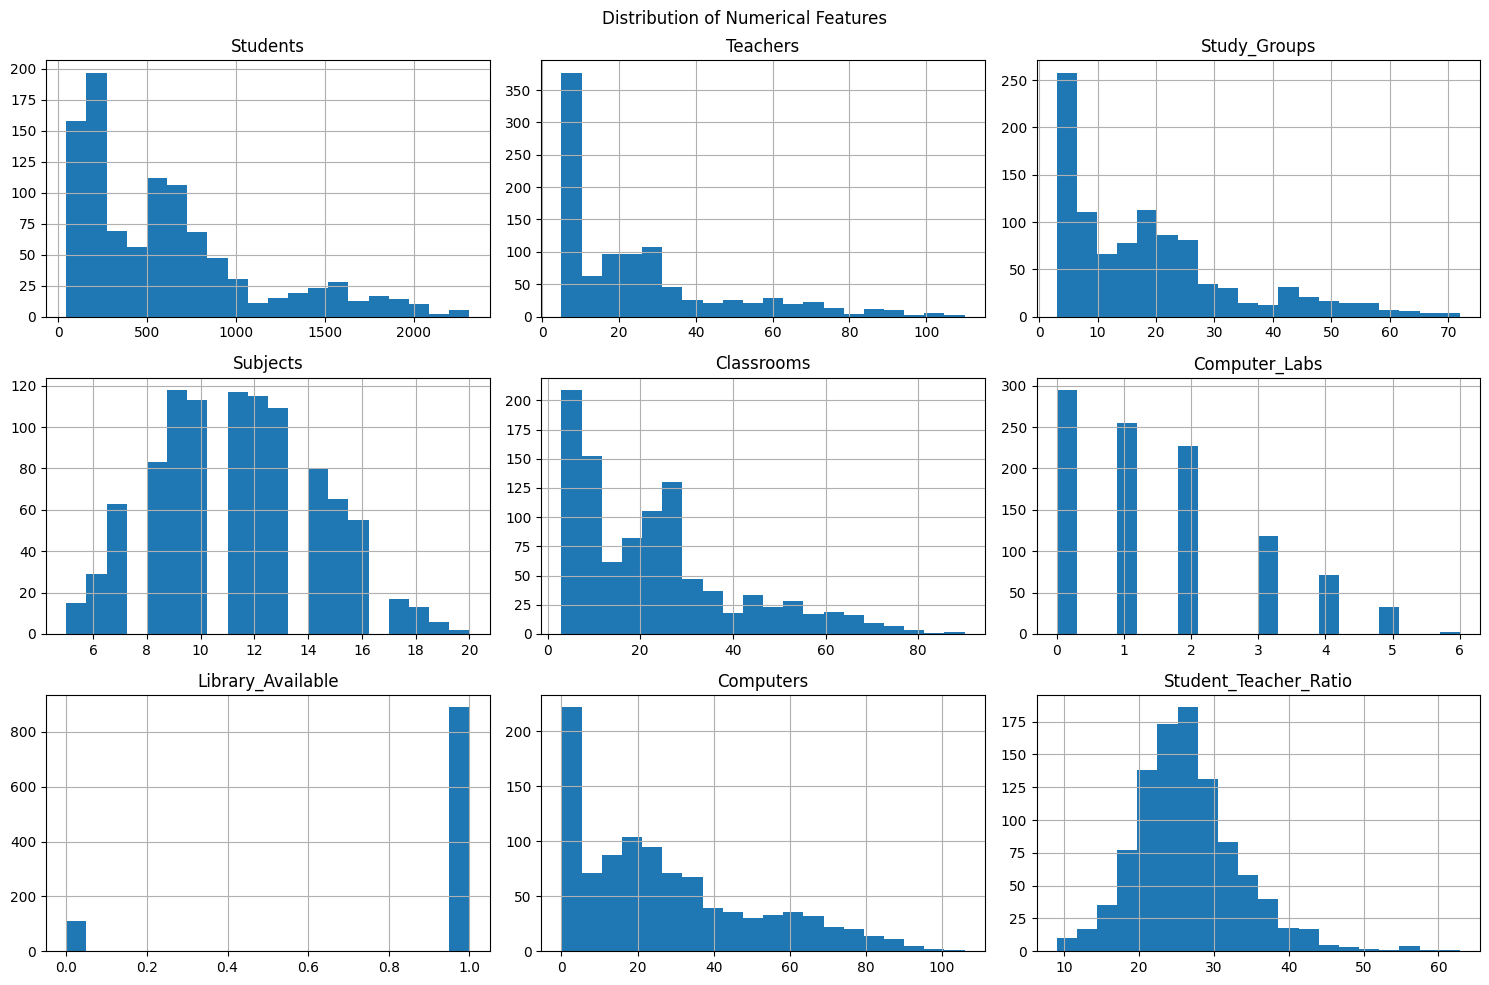

In [ ]:

# Cell 11: Plot numerical feature distributions

numerical_df.hist(figsize=(15, 10), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


In [ ]:

# Cell 12: Select clustering features

features = [
    "Students",
    "Teachers",
    "Study_Groups",
    "Subjects"
]

X = df[features]

print("Selected features:")
print(X.head())

print("\nDataset shape:", X.shape)


Selected features:
   Students  Teachers  Study_Groups  Subjects
0       625        26            19        10
1       698        37            24        13
2      1967        66            55        17
3       549        20            19        11
4        72         5             3         8

Dataset shape: (1000, 4)


In [ ]:

# Cell 13: Apply Min-Max Normalization

scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easy viewing
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled_df.head())


   Students  Teachers  Study_Groups  Subjects
0  0.255619  0.200000      0.231884  0.333333
1  0.287792  0.304762      0.304348  0.533333
2  0.847069  0.580952      0.753623  0.800000
3  0.222124  0.142857      0.231884  0.400000
4  0.011900  0.000000      0.000000  0.200000


In [ ]:

# Cell 14: Check minimum and maximum values

print("Minimum values:")
print(X_scaled_df.min())

print("\nMaximum values:")
print(X_scaled_df.max())


Minimum values:
Students        0.0
Teachers        0.0
Study_Groups    0.0
Subjects        0.0
dtype: float64

Maximum values:
Students        1.0
Teachers        1.0
Study_Groups    1.0
Subjects        1.0
dtype: float64


In [ ]:

# Experiment 2: Standard K-Means from scratch

def standard_kmeans(X, k, max_iterations=100, tolerance=0.0001):

    # Step 1: Initialize random centroids
    np.random.seed(42)

    random_indices = np.random.choice(
        len(X), k, replace=False
    )

    centroids = X[random_indices]

    for iteration in range(max_iterations):

        # Step 2: Calculate distances
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        # Step 3: Assign each observation to nearest centroid
        labels = np.argmin(distances, axis=1)

        # Step 4: Update centroids
        new_centroids = []

        for cluster in range(k):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:
                new_centroid = cluster_points.mean(axis=0)
            else:
                new_centroid = centroids[cluster]

            new_centroids.append(new_centroid)

        new_centroids = np.array(new_centroids)

        # Step 5: Check convergence
        difference = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        if difference < tolerance:
            break

    return labels, centroids, iteration + 1


In [ ]:

# Run Standard K-Means with K = 3

X_array = X_scaled_df.to_numpy()

labels, centroids, iterations = standard_kmeans(
    X_array,
    k=3
)

print("K-Means completed successfully!")
print("Number of clusters:", 3)
print("Number of iterations:", iterations)

print("\nCentroids:")
print(centroids)


K-Means completed successfully!
Number of clusters: 3
Number of iterations: 11

Centroids:
[[0.68647098 0.61829076 0.64497553 0.66269316]
 [0.28201597 0.21046245 0.2648063  0.49551282]
 [0.07134315 0.0256461  0.05281655 0.26004619]]


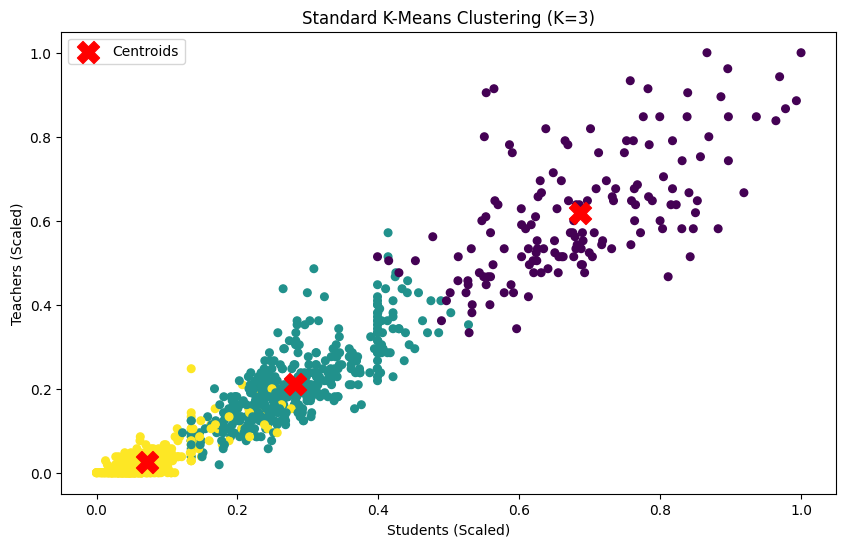

In [ ]:

# Cell 15: Visualize K-Means clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=30
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Students (Scaled)")
plt.ylabel("Teachers (Scaled)")
plt.title("Standard K-Means Clustering (K=3)")
plt.legend()
plt.show()


In [ ]:

# Cell 16: Calculate SSE

sse = 0

for i in range(len(X_array)):

    assigned_centroid = centroids[labels[i]]

    distance = np.linalg.norm(
        X_array[i] - assigned_centroid
    )

    sse += distance ** 2

print("Sum of Squared Errors (SSE):", sse)


Sum of Squared Errors (SSE): 37.862066102184826


In [ ]:

# Cell 17: Calculate Silhouette Score

score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)


Silhouette Score: 0.4957306487065443


In [ ]:

# Cell 18: Store baseline experiment results

baseline_results = pd.DataFrame({
    "Method": ["Random Initialization"],
    "K": [3],
    "Iterations": [iterations],
    "SSE": [sse],
    "Silhouette_Score": [score]
})

baseline_results


,Method,K,Iterations,SSE,Silhouette_Score
0,Random Initialization,3,11,37.862066,0.495731


In [ ]:

# Cell 19: Standard K-Means using Scikit-learn

from sklearn.cluster import KMeans

sklearn_kmeans = KMeans(
    n_clusters=3,
    init="random",
    n_init=1,
    max_iter=100,
    random_state=42,
    tol=0.0001
)

sklearn_labels = sklearn_kmeans.fit_predict(X_scaled)

sklearn_centroids = sklearn_kmeans.cluster_centers_

print("Scikit-learn K-Means")
print("--------------------")

print("Iterations:", sklearn_kmeans.n_iter_)
print("SSE:", sklearn_kmeans.inertia_)

print(
    "Silhouette Score:",
    silhouette_score(X_scaled, sklearn_labels)
)


Scikit-learn K-Means
--------------------
Iterations: 11
SSE: 37.86206610218481
Silhouette Score: 0.4957306487065443
